# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in `Samoa.json`).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.offshore_waves import boundary_parameters
from utils.snapwave_wrapper import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in Samoa.json → offshore_waves
period = "1989-09"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/WHACS/processed/Samoa_WHACS.zarr
goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-dynamic
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
period    : 1989-09


## Offshore waves → boundary forcing

In [3]:
import xarray as xr

offshore_ds = xr.concat(
    [
        open_offshore_waves(entry=offshore_entry).sel(
            time=slice("1989-09-01 01", "1990-04-11 19")
        ),
        open_offshore_waves(entry=offshore_entry).sel(
            time=slice("1990-05-16 21", "1991-11-19 06")
        ),
    ],
    dim="time",
).load()
offshore_ds

<xarray.Dataset> Size: 33MB
Dimensions:   (time: 18581, goal: 11)
Coordinates:
  * time      (time) datetime64[ns] 149kB 1989-09-01T01:00:00 ... 1991-11-19T...
  * goal      (goal) int64 88B 1 2 3 4 5 6 7 8 9 10 11
    seapoint  (goal) int64 88B 971044 971049 970816 ... 969776 970007 970465
Data variables: (12/20)
    dir       (time, goal) float64 2MB 104.0 94.7 95.6 ... 210.3 220.3 240.2
    hs        (time, goal) float64 2MB 1.982 1.914 1.932 ... 1.612 1.59 1.534
    pdir0     (time, goal) float64 2MB 85.6 93.2 93.2 97.7 ... nan nan nan nan
    pdir1     (time, goal) float64 2MB 215.8 220.5 142.5 ... 225.2 223.9 218.6
    pdir2     (time, goal) float64 2MB 168.8 105.7 216.8 ... 103.7 299.9 300.0
    pdir3     (time, goal) float64 2MB 165.0 288.1 102.7 ... 296.0 105.5 355.1
    ...        ...
    ptp0      (time, goal) float64 2MB 7.42 7.43 7.39 7.34 ... nan nan nan nan
    ptp1      (time, goal) float64 2MB 13.66 13.67 11.03 ... 11.39 11.32 11.46
    ptp2      (time, goal) float64 2MB 6.22 15.6 13.59 13.78 ... 7.63 9.43 9.34
    ptp3      (time, goal) float64 2MB 11.06 14.9 15.25 15.49 ... 9.56 7.69 9.58
    spr       (time, goal) float64 2MB 48.9 33.6 34.1 35.1 ... 51.4 51.5 59.0
    tp        (time, goal) float64 2MB 7.407 7.407 7.407 ... 11.36 11.36 11.24
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'dir_goals', 'spr_goals', 'tref']

## SnapWave wrapper

In [5]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-07-01 09:06:30,088 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-07-01 09:06:30,089 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-07-01 09:06:30,090 - SnapWaveDynamicModelWrapper - WARNING - Parameter dir_goals is not in the default_parameters
2026-07-01 09:06:30,090 - SnapWaveDynamicModelWrapper - WARNING - Parameter spr_goals is not in the default_parameters
2026-07-01 09:06:30,091 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters


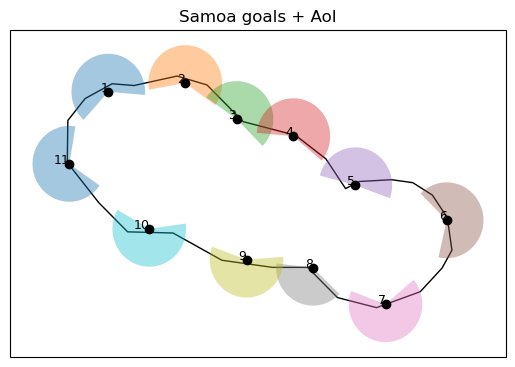

In [6]:
wrapper.plot_configuration()

In [7]:
wrapper.output_sites_df

,lon,lat,source,source_id,source_label,depth,name
0,-172.362339,-13.433536,isobath,5m_0,5m,-5.000000,NaN
1,-172.289348,-13.487306,isobath,5m_1,5m,-5.000000,NaN
2,-172.231790,-13.557491,isobath,5m_2,5m,-5.000000,NaN
3,-172.185137,-13.635869,isobath,5m_3,5m,-5.000000,NaN
4,-172.186410,-13.687549,isobath,5m_4,5m,-5.000000,NaN
...,...,...,...,...,...,...,...
626,-171.800626,-13.805272,mesh,Apia_14485,Apia,-0.774590,NaN
627,-171.727406,-13.840364,mesh,Apia_14531,Apia,-0.717097,NaN
628,-172.200000,-13.880000,buoy,buoy_Apolima_Buoy,waves,-80.000000,Savaii - Upolu middle buoy
629,-170.493000,-14.265000,buoy,buoy_American_Samoa_Buoy,waves,-75.000000,Ameican Samoa east buoy (Period 1)


## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
# wrapper.run_cases_in_background(launcher="default", num_workers=1)

In [10]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    18581
Name: count, dtype: int64

In [11]:
result = wrapper.postprocess_cases()
# out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_fullaso.nc"
result.to_netcdf(out_nc)

In [12]:
out_nc

PosixPath('/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_fullaso.nc')

In [13]:
import xarray as xr

xr.open_dataset(out_nc)

<xarray.Dataset> Size: 141MB
Dimensions:         (time: 18581, sites: 631)
Coordinates:
  * time            (time) datetime64[ns] 149kB 1989-09-01T01:00:00 ... 1991-...
  * sites           (sites) <U24 61kB '5m_0' '5m_1' ... 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 18kB ...
    site_label      (sites) <U5 13kB ...
    site_depth      (sites) float64 5kB ...
    site_longitude  (sites) float64 5kB ...
    site_latitude   (sites) float64 5kB ...
Data variables:
    hs              (time, sites) float32 47MB ...
    tp              (time, sites) float32 47MB ...
    dir             (time, sites) float32 47MB ...
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output